In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import tkinter as tk
from PIL import Image, ImageTk

1. Generating a matrix similar to the resolution of the SLM device - we are using HAMAMATSU LSH0805097
Resolution: 600 x 800

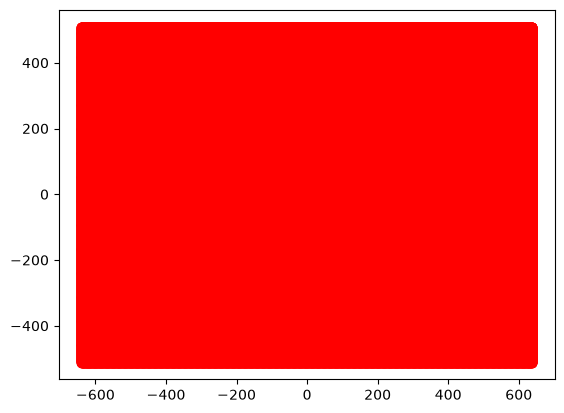

In [ ]:
H = 1280 #horizontal pixels - these are not the same as the camera yet so need to be changed
V = 1024 #vertical pixels

x = np.arange(-H/2,H/2-1,1)
y = np.arange(-V/2,V/2-1,1)

xv,yv = np.meshgrid(x,y) #surface area for the hologram - should be similar to that of SLMs resolution

phi = np.angle(xv + 1j * yv, deg=False) #azimuthal angle 
l = 1 #topological charge
# print(phi)
nx = 100 #number of horizontal and vertical grooves
ny = 100

gx = nx/H
gy = nx/V

plt.plot(xv,yv, marker='o', color='r', linestyle='none')
plt.show()

# plt.imshow(x,y)

2. Now that we have made a mesh similar to the size of the SLM screen, we encode a hologram on to it.

[[100.11596915 120.00688134 139.89773446 ... 202.82073707 222.71147164
  242.60226554]
 [125.05700903 144.94793452 164.83880086 ... 227.6843319  247.57507956
   12.46588664]
 [149.99810792 169.88904683 189.77992654 ... 252.54786719  17.43862809
   37.32944846]
 [174.93926587 194.83021835 214.72111156 ...  22.41134287  42.30211714
   62.19295094]
 [199.88048296 219.77144914 239.66235598 ...  47.27475888  67.16554665
   87.05639402]]


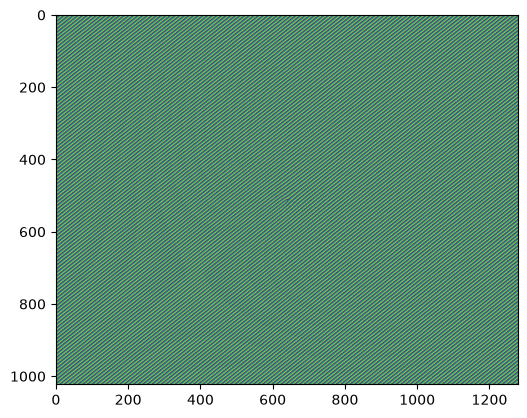

In [ ]:
#1. Vortex Beam
Hol_vortex = np.mod(-l*phi+2*np.pi*(gy*yv + gx*xv),2*np.pi)

#2. Bessel Beam


SLM_vortex = Hol_vortex/np.max(Hol_vortex) * 255 #grayscale normalisation

print(SLM_vortex[:5])
plt.imshow(SLM_vortex)
plt.show()

In [4]:
print(matplotlib.get_backend())

module://matplotlib_inline.backend_inline


3. Plotting the hologram on the second screen (the SLM)

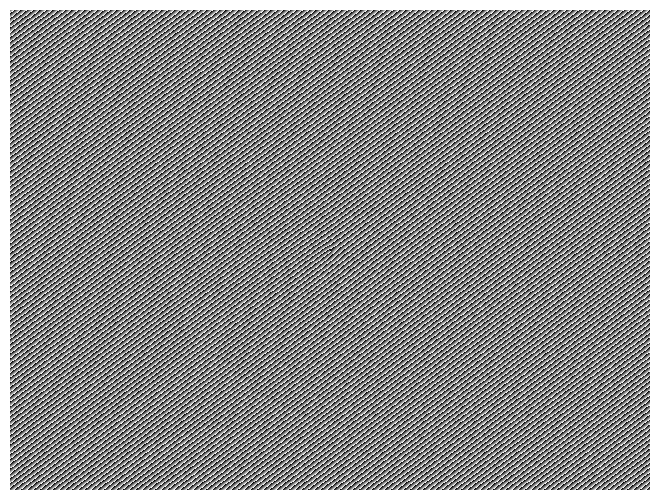

In [5]:
fig = plt.figure(1)

# Get the figure manager
manager = plt.get_current_fig_manager()

# Set window position if supported by the backend
if hasattr(manager, "window"):
    window = manager.window
    if hasattr(window, "wm_geometry"):  # Tkinter
        window.wm_geometry("+1200+0")
    elif hasattr(window, "setGeometry"):  # Qt
        window.setGeometry(1920, 0, 1280, 1024)

# Remove axes margins and display the SLM
ax = fig.add_axes([0, 0, 1, 1])
ax.imshow(SLM_vortex, cmap="gray", interpolation="nearest", aspect="auto")
ax.axis("off")

plt.show()

In [6]:
# # Convert SLM array to 8-bit grayscale
# image = np.asarray(SLM_vortex)

# if image.dtype != np.uint8:
#     image = np.clip(image, 0, 255).astype(np.uint8)

# pil_image = Image.fromarray(image, mode="L")

# # Create a borderless window
# root = tk.Tk()
# root.overrideredirect(True)

# # Set the position to your SLM monitor
# x, y = -300, 0
# root.geometry(f"{image.shape[1]}x{image.shape[0]}+{x}+{y}")

# # Display the image without margins
# photo = ImageTk.PhotoImage(pil_image)
# label = tk.Label(root, image=photo, borderwidth=0)
# label.pack()

# # Press Escape to close the window
# root.bind("<Escape>", lambda event: root.destroy())

# root.mainloop()

In [ ]:
# Check the image
image = np.asarray(SLM_vortex)

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Image range:", image.min(), image.max())

# Ensure an 8-bit grayscale image
image = np.clip(image, 0, 255).astype(np.uint8)
pil_image = Image.fromarray(image)

# Create display window
root = tk.Tk()
root.overrideredirect(True)
root.attributes("-topmost", True)

height, width = image.shape[:2]

# SLM monitor position
x, y = 1920, 0
root.geometry(f"{width}x{height}+{x}+{y}")

photo = ImageTk.PhotoImage(pil_image)
label = tk.Label(root, image=photo, borderwidth=0, highlightthickness=0)
label.pack()

root.bind("<Escape>", lambda event: root.destroy())

print("Window geometry:", root.geometry())
root.mainloop()

Image shape: (1023, 1279)
Image dtype: float64
Image range: 0.0 255.0
Window geometry: 1x1+1920+0


In [1]:
from screeninfo import get_monitors

for i, m in enumerate(get_monitors()):
    print(
        f"Monitor {i}: "
        f"x={m.x}, y={m.y}, "
        f"width={m.width}, height={m.height}"
    )

Monitor 0: x=0, y=0, width=1920, height=1080
Monitor 1: x=1920, y=0, width=1280, height=1024
